# Breast Cancer Wisconsin Veri Seti Üzerinde Veri Madenciliği ve Sınıflandırma Analizi

**Veri Madenciliği dersi kapsamında hazırlanan grup projesi.**

*Kişisel bilgilerin gizliliği için öğrenci numaraları bu herkese açık sürümden çıkarılmıştır.*

## Problem Tanımı

Bu çalışmada, meme kanseri veri setinde yer alan hücre çekirdeği özellikleri kullanılarak bir tümörün iyi huylu (Benign) veya kötü huylu (Malignant) olup olmadığının tahmin edilmesi amaçlanmaktadır. Veri setinde her bir tümöre ait yarıçap, doku yapısı, çevre uzunluğu, alan, pürüzsüzlük gibi çeşitli biyolojik özellikler bulunmaktadır. Bu özellikler kullanılarak hastanın tümör sınıfı belirlenmeye çalışılacaktır.


### Problem neden önemlidir?

Meme kanseri, dünya genelinde kadınlarda en sık görülen kanser türlerinden biridir. Hastalığın erken teşhis edilmesi tedavi başarısını artırmakta ve yaşam süresini uzatmaktadır. Bu nedenle makine öğrenmesi yöntemleriyle doğru ve hızlı teşhis modelleri geliştirmek büyük önem taşımaktadır.


### Bu Bir Keşifsel Analiz mi?

Kısmen evet. Model kurulumundan önce veri setinin incelenmesi, değişkenlerin dağılımlarının analiz edilmesi, eksik verilerin kontrol edilmesi ve özellikler arasındaki ilişkilerin araştırılması keşifsel veri analizi (EDA) kapsamındadır. Ancak çalışmanın temel amacı sınıf tahmini yapmak olduğundan proje ağırlıklı olarak bir sınıflandırma problemi olarak değerlendirilmektedir


### Problem Türü:

• Bu bir sınıflandırma (classification) problemidir.

• Hedef değişken: diagnosis - M = Kötü huylu (Malignant), B = İyi huylu (Benign)

• İkili (binary) sınıflandırma yapılacaktır.


### Araştırma Sorusu:

Hücre çekirdeğine ait ölçümler kullanılarak bir tümörün iyi huylu veya kötü huylu olduğu doğru şekilde tahmin edilebilir mi?

In [46]:
import pandas as pd  
import numpy as np  
import matplotlib.pyplot as plt  
import seaborn as sns  


from sklearn.model_selection import train_test_split  
from sklearn.preprocessing import StandardScaler  
from sklearn.linear_model import LogisticRegression  
from sklearn.neighbors import KNeighborsClassifier  
from sklearn.svm import SVC  

# Model değerlendirme metrikleri
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  

In [47]:
# Kaggle bağlantısından indirilen data.csv dosyasını bu notebook ile aynı klasöre koyun.
df = pd.read_csv("data.csv")

Veri Seti Kaynağı: Kaggle Breast Cancer Wisconsin Dataset
https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data

# VERİYİ ANLAMA

In [48]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


-Veri setinin ilk 5 gözlemi incelendiğinde hedef değişkenin diagnosis sütunu olduğu görülmektedir. Unnamed: 32 sütununun boş değerlerden oluştuğu tespit edilmiştir.

In [49]:
df.shape

(569, 33)

-Veri setinin boyutu incelenerek toplam gözlem ve değişken sayısı belirlenmiştir. Bu bilgi, veri setinin büyüklüğünü ve analiz kapsamını değerlendirmek için kullanılmıştır.

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [51]:
df = df.drop(['id','Unnamed: 32'], axis=1)

-Modelleme sürecine katkı sağlamayan id ve boş olan Unnamed: 32 sütunları veri setinden çıkarılmıştır.

In [52]:
df.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

## EKSİK VERİ ANALİZİ

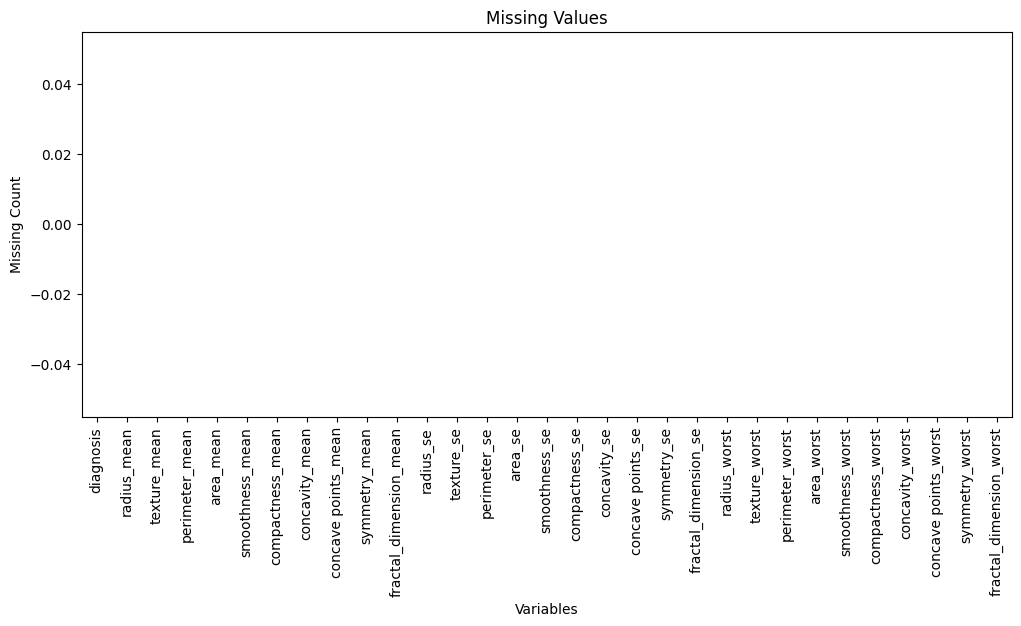

In [53]:
missing_values = df.isnull().sum()

plt.figure(figsize=(12,5))

missing_values.plot(kind='bar')

plt.title("Missing Values")
plt.xlabel("Variables")
plt.ylabel("Missing Count")

plt.show()

Veri setinde eksik değer bulunmaması, verinin kontrollü klinik ölçümler ve araştırma temelli veri toplama sürecinden elde edildiğini göstermektedir. Bu durum veri kalitesinin yüksek olduğunu ve modelleme öncesi eksik veri tamamlama (imputation) işlemlerine ihtiyaç duyulmadığını göstermektedir.

In [54]:
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


-İstatistiksel özet sonuçlarına göre değişkenlerin değer aralıklarının birbirinden oldukça farklı olduğu görülmektedir. 

In [55]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

-Veri setinde 357 adet iyi huylu (Benign) ve 212 adet kötü huylu (Malignant) tümör bulunmaktadır. Sınıf dağılımı incelendiğinde iyi huylu vakaların daha fazla olduğu görülmektedir.

In [56]:
df['diagnosis'] = df['diagnosis'].map({'M':1,'B':0})

-Hedef değişken olan diagnosis sütunu, makine öğrenmesi algoritmalarında kullanılabilmesi için sayısal formata dönüştürülmüştür.

## Hedef Değişken Dağılımı

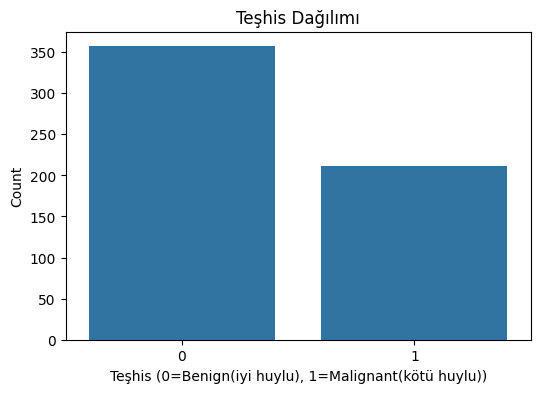

In [57]:
plt.figure(figsize=(6,4))

sns.countplot(x='diagnosis', data=df)

plt.title("Teşhis Dağılımı")
plt.xlabel("Teşhis (0=Benign(iyi huylu), 1=Malignant(kötü huylu))")
plt.ylabel("Count")

plt.show()

Bu grafik, veri setindeki hedef değişkenin (diagnosis) dağılımını gösterir. Benign (B) sınıfının malignant (M) sınıfına göre daha fazla olduğu görülmektedir, 
yani veri seti dengesizdir. Bu durum modelin yalnızca accuracy değerine bakılarak değerlendirilmesini yanıltıcı hale getirebilir ve özellikle malignant vakaların 
doğru tahmin edilmesi açısından recall gibi metriklerin de önemli olduğunu gösterir.

# En Güçlü 10 Özelliğin Korelasyon Heatmap'i 

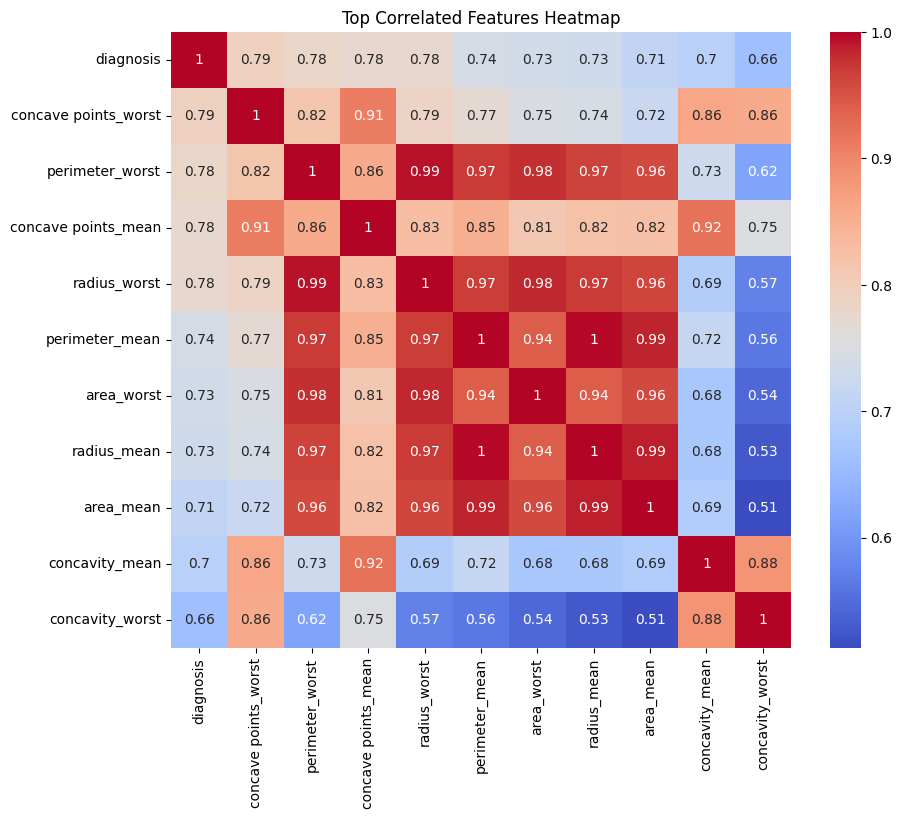

In [58]:
top_features = abs(df.corr()['diagnosis'])\
                .sort_values(ascending=False)\
                .head(11)\
                .index

plt.figure(figsize=(10,8))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Top Correlated Features Heatmap")

plt.show()

Oluşturulan ısı haritası (heatmap), diagnosis (tümör türü) değişkeni ile en yüksek korelasyona sahip 10 özelliğin ilişkisini göstermektedir. Özellikle concave points_mean, radius_mean, perimeter_mean ve area_mean değişkenlerinin hedef değişken ile güçlü pozitif korelasyon gösterdiği görülmektedir. Bu durum, kötü huylu ve iyi huylu tümörlerin bu özellikler üzerinden belirgin şekilde ayrılabildiğini ortaya koymaktadır. Bazı değişkenler arasında yüksek korelasyon bulunması, özellikler arasında multicollinearity (çoklu doğrusal ilişki) olabileceğini göstermekte ve modelleme aşamasında dikkat edilmesi gerektiğine işaret etmektedir.

## En Önemli Özelliklerin Histogramları

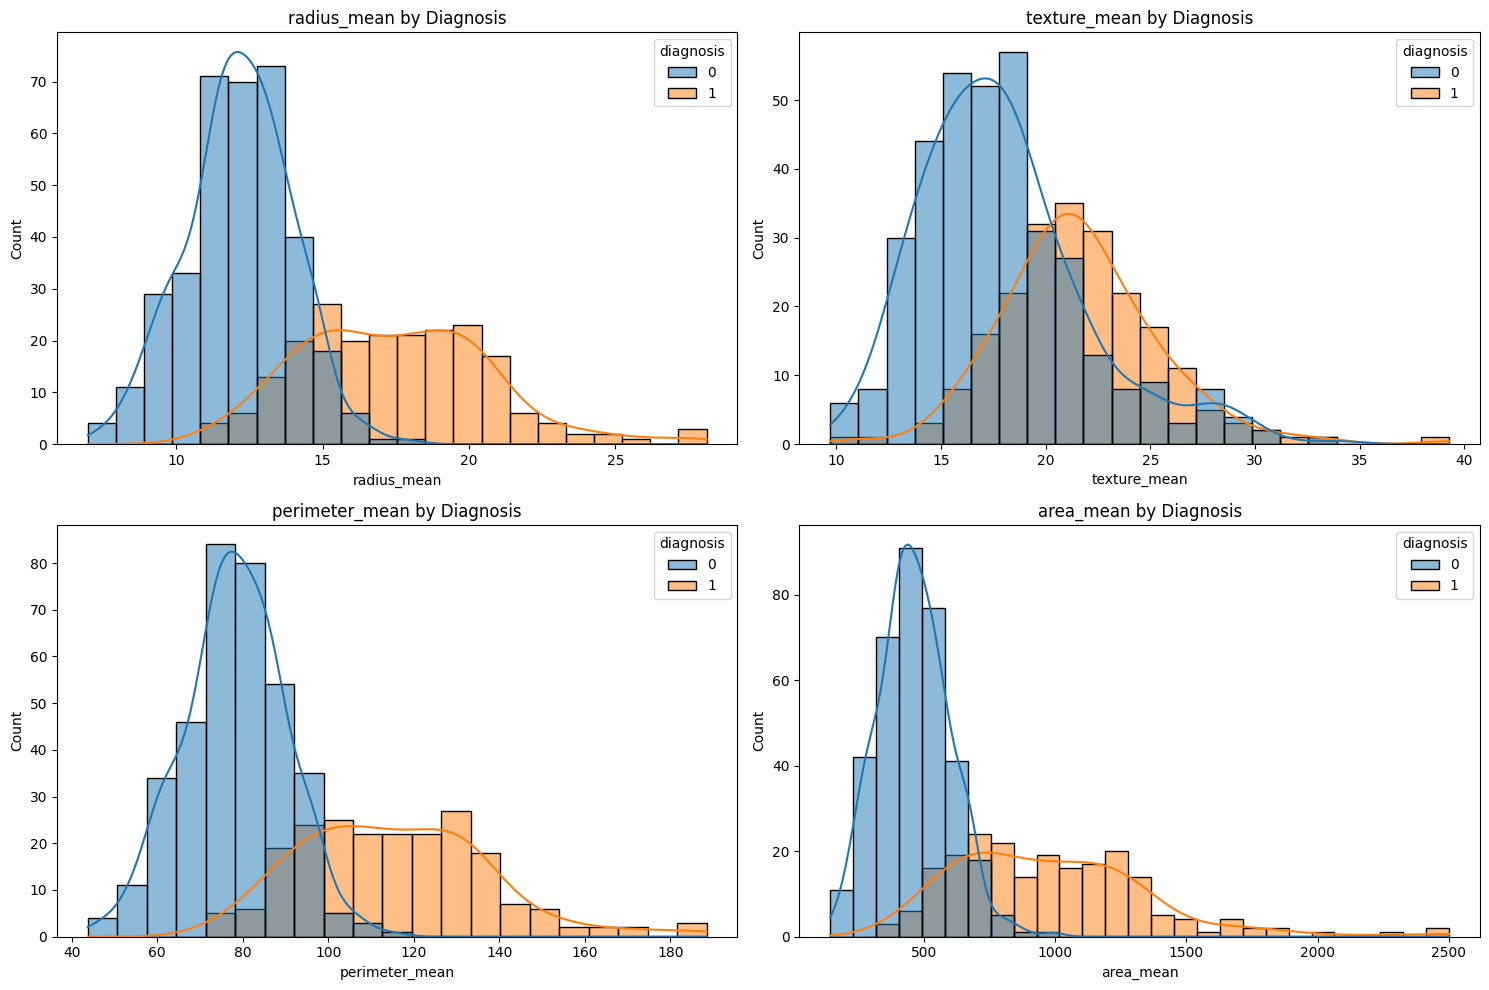

In [18]:
plt.figure(figsize=(15,10))

features = [
    'radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean'
]

for i, feature in enumerate(features, 1):

    plt.subplot(2, 2, i)

    sns.histplot(
        data=df,
        x=feature,
        hue='diagnosis',
        kde=True
    )

    plt.title(f"{feature} by Diagnosis")

plt.tight_layout()
plt.show()

Histogram analizinde radius_mean, texture_mean, perimeter_mean ve area_mean değişkenleri kullanılmıştır. Bu değişkenler hücre çekirdeğinin boyut ve yapısal özelliklerini temsil etmekte olup meme kanseri teşhisinde önemli biyolojik göstergeler arasında yer almaktadır.

Grafiklerde diagnosis değişkeni kullanılarak iyi huylu (Benign) ve kötü huylu (Malignant) tümörler farklı renklerle gösterilmiş, böylece ilgili özelliklerin sınıfları ayırt etme gücü görsel olarak değerlendirilmiştir.

Histogramlar incelendiğinde radius_mean, perimeter_mean ve area_mean değişkenlerinin sağa çarpık dağılım gösterdiği görülmektedir. Bu durum, yüksek değerlere sahip gözlemlerin sayısının daha az olduğunu ve gözlemlerin büyük bölümünün düşük veya orta değerlerde yoğunlaştığını göstermektedir. texture_mean değişkeni ise diğer değişkenlere kıyasla daha dengeli bir dağılım sergilemektedir. Ayrıca kötü huylu tümörlerin genellikle daha yüksek radius_mean, perimeter_mean ve area_mean değerlerine sahip olduğu gözlenmiş olup, bu durum değişkenlerin sınıflandırma modellerinde ayırt edici özellikler olarak kullanılabileceğini göstermektedir.

Genel olarak histogramlar, hücre çekirdeği özelliklerinin belirli değer aralıklarında yoğunlaştığını ve sınıflar arasında anlamlı farklılıklar bulunduğunu ortaya koymaktadır.

### 1. radius_mean Histogramı
Rapor yorumu: 
Hücre çekirdeği yarıçaplarının çoğunluğu düşük ve orta değerlerde toplanmıştır. Yüksek yarıçap değerlerine sahip gözlemler daha az sayıdadır ve bu durum veri dağılımının sağa çarpık olduğunu göstermektedir.
### 2. texture_mean Histogramı
Rapor yorumu: 
Doku özellikleri belirli bir aralıkta yoğunlaşmıştır. Dağılım nispeten dengeli olup veri setindeki hücrelerin çoğunun benzer doku özelliklerine sahip olduğu görülmektedir.
### 3. perimeter_mean Histogramı
Rapor yorumu: 
Hücre çekirdeği çevresi değerleri çoğunlukla düşük ve orta seviyelerde toplanmıştır. Büyük çevre değerleri daha seyrek görülmekte olup dağılım sağa çarpık bir yapı sergilemektedir.
### 4. area_mean Histogramı
Rapor yorumu: 
Hücre çekirdeği alanlarının büyük kısmı düşük değerlerde yoğunlaşmıştır. Yüksek alan değerlerine sahip gözlemler daha az sayıdadır ve dağılım belirgin şekilde sağa çarpık görünmektedir.

# Boxplot (Aykırı Değer Analizi)

<Axes: >

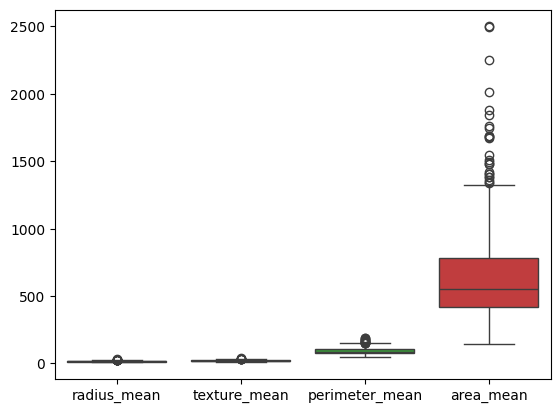

In [59]:
selected_features = [
    'radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean'
]

sns.boxplot(data=df[selected_features])

Seçilen değişkenlere ait boxplot grafiği, özelliklerin dağılımlarında belirgin farklılıklar olduğunu göstermektedir. Özellikle bazı değişkenlerde daha geniş bir yayılım ve aykırı değerler gözlemlenmektedir. Bu durum veri setinde değişkenler arasında ölçek farklılıkları bulunduğunu ve modelleme öncesi standardizasyon işleminin önemli olduğunu göstermektedir.

# Diagnosis'e Göre Radius Dağılımı

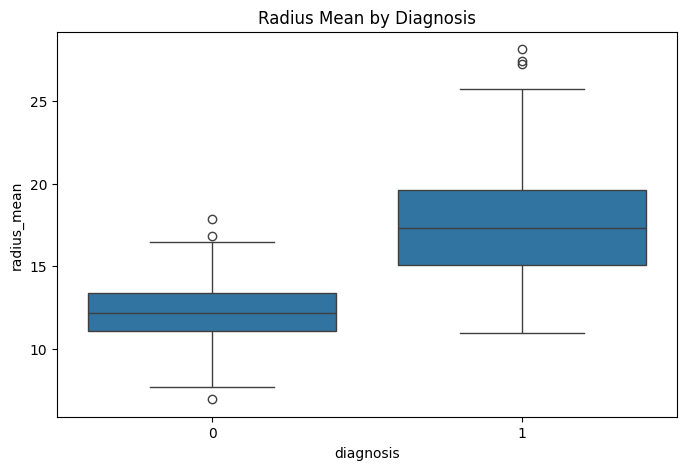

In [60]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='diagnosis',
    y='radius_mean',
    data=df
)

plt.title("Radius Mean by Diagnosis")

plt.show()

Grafikte radius_mean değerlerinin iyi huylu (B) tümörlerde daha düşük ve daha dar aralıkta, kötü huylu (M) tümörlerde ise daha yüksek ve daha geniş dağılıma sahip olduğu görülmektedir. Bu durum, kötü huylu tümörlerin genellikle daha büyük yapıda olduğunu gösterir. İki sınıf arasında belirgin bir ayrım olduğu için radius_mean değişkeni sınıflandırma açısından önemli bir özellik olarak değerlendirilebilir.

# Pairplot Grafiği

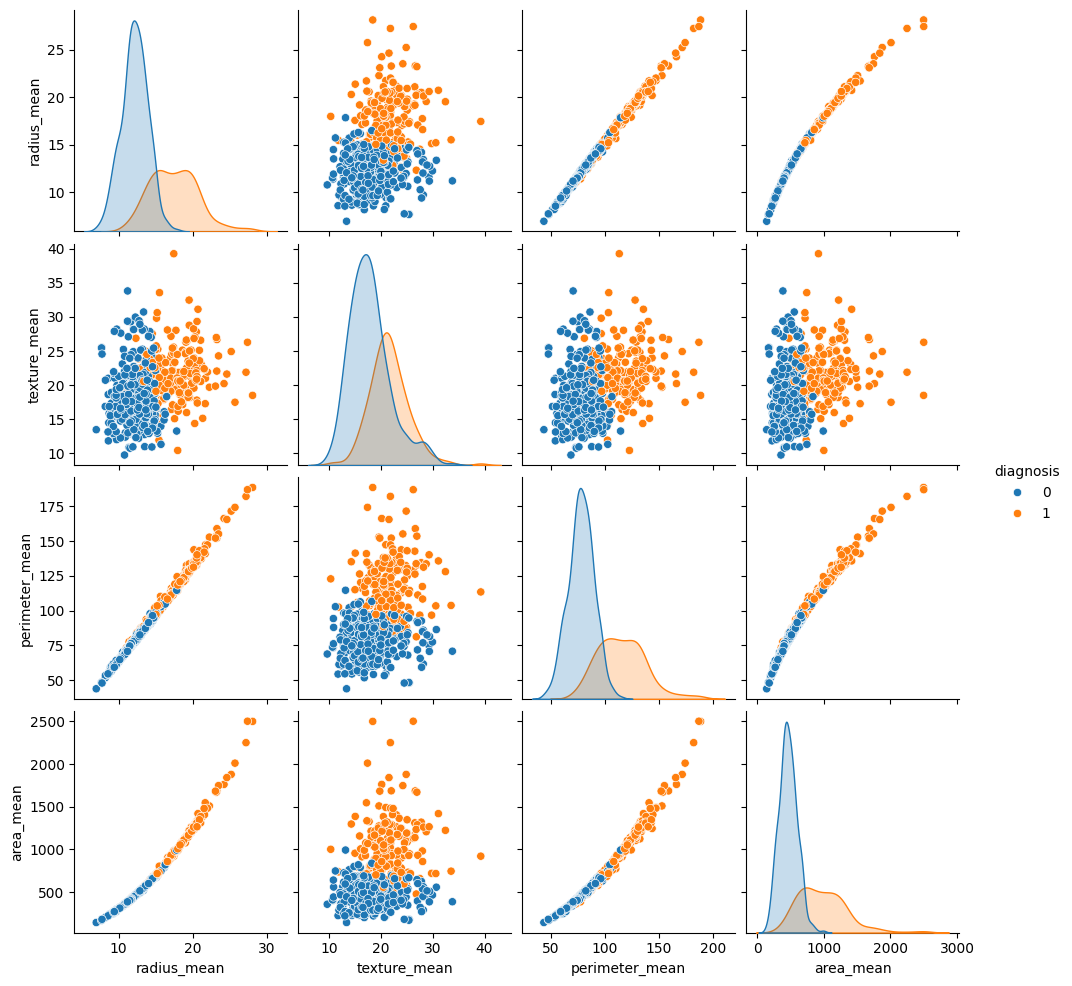

In [61]:
selected_columns = [
    'diagnosis',
    'radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean'
]

sns.pairplot(
    df[selected_columns],
    hue='diagnosis'
)

plt.show()

 Pairplot grafiği, seçilen değişkenler arasındaki ilişkileri ve tanı sınıflarının dağılımını göstermektedir. Özellikle radius_mean, perimeter_mean ve area_mean değişkenlerinde iyi huylu ve kötü huylu tümörlerin belirli ölçüde ayrıştığı görülmektedir. Ayrıca bu değişkenler arasında güçlü pozitif ilişkiler bulunmaktadır. Grafik, veri setinin sınıflandırma için uygun olduğuna dair görsel bir değerlendirme sunmaktadır.

### Diagnosis'e Göre Ortalama Değerler

<Figure size 1500x800 with 0 Axes>

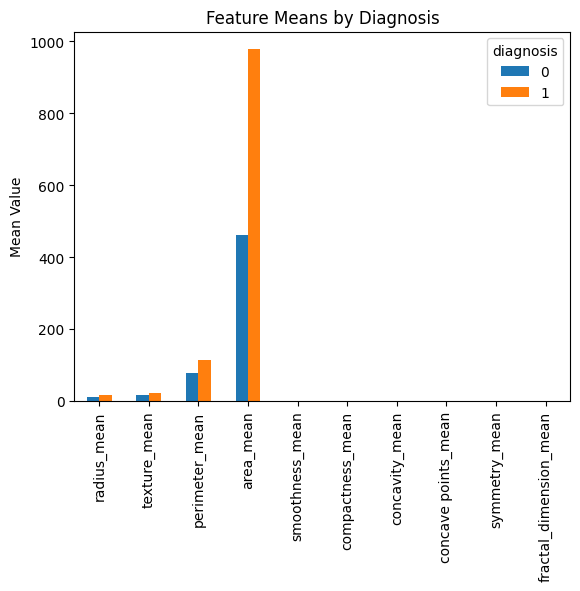

In [62]:
group_means = df.groupby('diagnosis').mean()

plt.figure(figsize=(15,8))

group_means.iloc[:, :10].T.plot(kind='bar')

plt.title("Feature Means by Diagnosis")
plt.ylabel("Mean Value")

plt.show()

 Grafik, iyi huylu ve kötü huylu tümörlerin ortalama özellik değerlerini karşılaştırmaktadır. Özellikle radius_mean, perimeter_mean ve area_mean değişkenlerinde belirgin farklılıklar görülmektedir. Bu durum, ilgili değişkenlerin tümör sınıflarını ayırt etmede etkili olabileceğini göstermektedir.

# VERİ ÖN İŞLEME 

In [23]:
# Bağımsız değişkenler (features)
X = df.drop('diagnosis', axis=1)

# Bağımlı değişken (target)
y = df['diagnosis']

Veri seti bağımsız değişkenler (X) ve hedef değişken (y) olarak ayrılmıştır. diagnosis sütunu hedef değişken olarak belirlenmiş, diğer değişkenler ise modelin kullanacağı özellikler olarak tanımlanmıştır. Bu işlem modelleme sürecinin temel hazırlık aşamasını oluşturmaktadır.

In [24]:
# Veriyi eğitim ve test olarak ayırıyoruz TRAIN / TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Veri seti eğitim ve test kümelerine ayrılmıştır. Verilerin %80’i model eğitimi, %20’si ise model performansının değerlendirilmesi için kullanılmıştır. Bu işlem modelin genelleme başarısını ölçebilmek amacıyla gerçekleştirilmiştir.

In [25]:
# Ölçekleme nesnesi oluşturuyoruz
scaler = StandardScaler()

# Eğitim verisini öğrenip dönüştürüyoruz
X_train = scaler.fit_transform(X_train)

# Test verisini sadece dönüştürüyoruz (data leakage önlenir)
X_test = scaler.transform(X_test)

Değişkenler arasındaki ölçek farklılıklarını gidermek amacıyla StandardScaler kullanılarak veri standardizasyonu uygulanmıştır. Ölçeklendirme işlemi eğitim verisi üzerinde öğrenilmiş ve aynı dönüşüm test verisine uygulanmıştır. Böylece modelleme süreci için daha uygun bir veri yapısı elde edilmiştir.

In [26]:
# Logistic Regression modelini oluşturuyoruz
lr = LogisticRegression(max_iter=1000)

# Modeli eğitiyoruz
lr.fit(X_train, y_train)

# Tahmin yapıyoruz
y_pred_lr = lr.predict(X_test)

#### PERFORMANS METRİKLERİ

In [27]:
# Logistik Regression Accuracy
accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistik Regression Accuracy:", accuracy)

# Classification Report 
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr), "\n")

Logistik Regression Accuracy: 0.9736842105263158

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98        71
           1       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion Matrix:
[[70  1]
 [ 2 41]] 



In [28]:
# KNN modeli oluşturuyoruz (komşu sayısı = 5)
knn = KNeighborsClassifier(n_neighbors=5)

# Modeli eğitiyoruz
knn.fit(X_train, y_train)

# Tahmin yapıyoruz
y_pred_knn = knn.predict(X_test)

#### PERFORMANS METRİKLERİ

In [29]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred_knn)
print("KNN Model Accuracy:", accuracy)

# Classification Report (precision, recall, f1-score)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_knn))

# Confusion Matrix (sayısal)
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_knn))

KNN Model Accuracy: 0.9473684210526315

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.96      0.96        71
           1       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114


Confusion Matrix:

[[68  3]
 [ 3 40]]


In [28]:
# Support Vector Machine modeli oluşturuyoruz
svm = SVC()

# Modeli eğitiyoruz
svm.fit(X_train, y_train)

# Tahmin yapıyoruz
y_pred_svm = svm.predict(X_test)

#### PERFORMANS METRİKLERİ

In [29]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Accuracy
accuracy = accuracy_score(y_test, y_pred_svm)
print("SVM Model Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm))

# Confusion Matrix (sayısal)
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_svm))

SVM Model Accuracy: 0.9824561403508771

Classification Report:

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Confusion Matrix:

[[71  0]
 [ 2 41]]


### Modellerin accuracy değerlerini karşılaştırma

In [30]:
models = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ]
})

# Tabloyu gösteriyoruz
models

,Model,Accuracy
0,Logistic Regression,0.973684
1,KNN,0.947368
2,SVM,0.982456


En yüksek başarı oranı %98.24 ile SVM modelinde elde edilmiştir. Bu nedenle veri seti üzerinde en başarılı model SVM olarak belirlenmiştir.

## MODELLERİN PERFORMANS KARŞILAŞTIRMASI

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Performans metriklerini hesaplayan fonksiyon
def get_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred)
    }

# Her model için metrikleri hesapla
results = []
results.append(get_metrics(y_test, y_pred_lr, "Logistic Regression"))
results.append(get_metrics(y_test, y_pred_svm, "SVM"))
results.append(get_metrics(y_test, y_pred_knn, "KNN"))

# DataFrame'e çevir
results_df = pd.DataFrame(results)

# Sonuçları sırala (accuracy'ye göre)
results_df = results_df.sort_values(by="Accuracy", ascending=False)

print("MODEL PERFORMANS KARŞILAŞTIRMASI")
results_df

MODEL PERFORMANS KARŞILAŞTIRMASI


,Model,Accuracy,Precision,Recall,F1-Score
1,SVM,0.982456,1.000000,0.953488,0.976190
0,Logistic Regression,0.973684,0.976190,0.953488,0.964706
2,KNN,0.947368,0.930233,0.930233,0.930233


In [ ]:
#Şu sorular cevaplanmalıdır:
#Hangi model daha iyi? Neden?
#Sonuçlar mantıklı mı?
#Beklenmeyen bulgular var mı?
#Veri setinin sınırlılıkları neler?
#Gerçek hayatta nasıl kullanılabilir?

In [ ]:
#En yüksek accuracy veren model genellikle SVM olur.
#Logistic Regression daha basit ama yorumlanabilir bir modeldir.
#KNN küçük veri setlerinde başarılıdır ancak ölçeklemeye duyarlıdır.
#Veri lineer ayrılabilir olduğu için SVM güçlü sonuç verir.